In [289]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score 
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

import matplotlib.pyplot as plt 

In [245]:
data = pd.read_csv('../data/Customer-Churn-Records.csv')
data

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339


In [246]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [247]:
data.isnull().sum()

RowNumber             0
CustomerId            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64

In [248]:
data.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain',
       'Satisfaction Score', 'Card Type', 'Point Earned'],
      dtype='str')

In [249]:
data.duplicated().sum()

np.int64(0)

In [250]:
data.shape

(10000, 18)

In [251]:
data.Geography.value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [252]:
data["Card Type"].value_counts()

Card Type
DIAMOND     2507
GOLD        2502
SILVER      2496
PLATINUM    2495
Name: count, dtype: int64

In [253]:
data.Surname.value_counts()

Surname
Smith        32
Scott        29
Martin       29
Walker       28
Brown        26
             ..
Salinas       1
Cleveland     1
Kashiwagi     1
Aldridge      1
Burbidge      1
Name: count, Length: 2932, dtype: int64

In [254]:
# Drop RowNumber, CustomerId, Surname

data.drop(columns=['RowNumber', 'CustomerId', 'Surname'],inplace=True)

In [255]:
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [256]:
label_encoder = LabelEncoder()

In [257]:
data['Geography'] = label_encoder.fit_transform(data['Geography'])
data['Gender'] = label_encoder.fit_transform(data['Gender'])
data['Card Type'] = label_encoder.fit_transform(data['Card Type'])

In [258]:
data.sample(10)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
8063,549,1,1,34,6,204017.40,2,1,0,109538.35,0,0,1,1,872
4923,651,1,1,34,2,90355.12,2,0,0,193597.94,0,0,3,1,576
5437,543,1,1,30,6,73481.05,1,1,1,176692.65,0,0,3,1,683
3546,542,2,1,43,6,113567.94,1,1,0,89543.25,0,0,5,3,237
9340,737,0,1,45,10,0.00,2,1,0,1364.54,0,0,5,1,531
1743,476,0,1,40,6,0.00,1,1,1,22735.45,0,0,4,2,507
3740,649,0,1,45,7,0.00,2,0,1,75204.21,0,0,1,0,873
1119,756,2,1,29,2,117412.19,2,1,0,4888.91,0,0,1,0,565
397,547,1,1,32,8,155726.85,1,1,0,67789.99,0,0,2,3,309
1334,489,1,1,28,1,79460.98,2,1,1,167973.63,0,0,3,2,232


In [259]:
data = pd.get_dummies(data,columns=['Geography'],drop_first=True,dtype=int)

In [260]:
data

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,Geography_1,Geography_2
0,619,0,42,2,0.00,1,1,1,101348.88,1,1,2,0,464,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,1,3,0,456,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1,3,0,377,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,5,1,350,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,5,1,425,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,1,39,5,0.00,2,1,0,96270.64,0,0,1,0,300,0,0
9996,516,1,35,10,57369.61,1,1,1,101699.77,0,0,5,2,771,0,0
9997,709,0,36,7,0.00,1,0,1,42085.58,1,1,3,3,564,0,0
9998,772,1,42,3,75075.31,2,1,0,92888.52,1,1,2,1,339,1,0


In [261]:
data = pd.get_dummies(data,columns=['Card Type'],drop_first=True,dtype=int)

In [262]:
data.sample(10)

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned,Geography_1,Geography_2,Card Type_1,Card Type_2,Card Type_3
1993,824,1,60,8,134250.17,3,0,0,153046.16,1,1,4,244,1,0,1,0,0
6333,634,1,34,8,105302.66,1,1,1,123164.97,0,0,1,378,0,0,0,0,0
9115,612,0,36,2,130700.92,2,0,0,77592.80,0,0,5,351,1,0,0,0,0
3749,427,1,33,8,0.00,1,1,1,13858.95,0,0,4,959,0,0,0,0,1
3142,697,0,76,7,0.00,2,0,1,188772.45,0,0,3,733,0,0,0,0,0
1832,620,1,22,0,0.00,1,1,0,32589.45,0,0,3,911,0,0,1,0,0
8814,740,0,51,4,0.00,2,1,1,178929.84,0,0,4,850,0,0,0,0,1
3211,686,0,27,1,115095.88,2,0,0,78622.46,0,0,2,873,1,0,0,0,0
4845,655,0,36,2,147149.59,1,1,1,87816.86,0,0,5,680,0,0,1,0,0
2310,781,1,32,6,147107.91,1,1,1,40066.95,0,0,1,740,0,0,0,1,0


In [263]:
X = data.drop(columns=["Exited"]).values

In [264]:
X.shape

(10000, 17)

In [265]:
X

array([[619.,   0.,  42., ...,   0.,   0.,   0.],
       [608.,   0.,  41., ...,   0.,   0.,   0.],
       [502.,   0.,  42., ...,   0.,   0.,   0.],
       ...,
       [709.,   0.,  36., ...,   0.,   0.,   1.],
       [772.,   1.,  42., ...,   1.,   0.,   0.],
       [792.,   0.,  28., ...,   0.,   0.,   0.]], shape=(10000, 17))

In [266]:
y = data["Exited"].values

In [267]:
y

array([1, 0, 1, ..., 1, 1, 0], shape=(10000,))

In [268]:
scaler = StandardScaler()

In [269]:
X = scaler.fit_transform(X)
X

array([[-0.32622142, -1.09598752,  0.29351742, ..., -0.57765819,
        -0.57658047, -0.57673443],
       [-0.44003595, -1.09598752,  0.19816383, ..., -0.57765819,
        -0.57658047, -0.57673443],
       [-1.53679418, -1.09598752,  0.29351742, ..., -0.57765819,
        -0.57658047, -0.57673443],
       ...,
       [ 0.60498839, -1.09598752, -0.27860412, ..., -0.57765819,
        -0.57658047,  1.7339003 ],
       [ 1.25683526,  0.91241915,  0.29351742, ...,  1.73112754,
        -0.57658047, -0.57673443],
       [ 1.46377078, -1.09598752, -1.04143285, ..., -0.57765819,
        -0.57658047, -0.57673443]], shape=(10000, 17))

In [270]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [271]:
X_train.shape

(8000, 17)

In [272]:
X_test.shape

(2000, 17)

In [273]:
y.shape

(10000,)

In [274]:
model = Sequential()

In [275]:
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(7, activation='relu'))
model.add(Dense(3, activation='relu'))
model.add(Dense(2, activation='relu'))
model.add(Dense(1, activation='sigmoid'))


In [276]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 7)              │           126 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 2)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [277]:
17 * 7

119

In [278]:
119 + 7

126

In [279]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [280]:
history = model.fit(X_train,y_train,batch_size=50,epochs=100,verbose=1,validation_split=0.2)
history

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7956 - loss: 0.5522 - val_accuracy: 0.7969 - val_loss: 0.4624
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step - accuracy: 0.7956 - loss: 0.3897 - val_accuracy: 0.7969 - val_loss: 0.3209
Epoch 3/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step - accuracy: 0.7956 - loss: 0.2524 - val_accuracy: 0.7969 - val_loss: 0.2016
Epoch 4/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 456us/step - accuracy: 0.8973 - loss: 0.1735 - val_accuracy: 0.9775 - val_loss: 0.1547
Epoch 5/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 439us/step - accuracy: 0.9887 - loss: 0.1451 - val_accuracy: 0.9912 - val_loss: 0.1340
Epoch 6/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 448us/step - accuracy: 0.9945 - loss: 0.1295 - val_accuracy: 0.9950 - val_loss: 0.1201
Epoch 7/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step - accuracy: 0.9964 - loss: 0.1177 - val_accuracy: 0.9969 - val_loss: 0.1094
Epoch 8/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step - accuracy: 0.9975 - loss: 0.1

In [281]:
y_pred = model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 578us/step


In [282]:
y_pred

array([[2.3224836e-13],
       [9.9057198e-01],
       [1.8099210e-10],
       ...,
       [2.3263829e-07],
       [6.9224987e-14],
       [2.4424768e-12]], shape=(2000, 1), dtype=float32)

In [283]:
y_test

array([0, 1, 0, ..., 0, 0, 0], shape=(2000,))

In [284]:
y_pred = (y_pred > 0.5).astype("int32").ravel()

In [285]:
y_pred

array([0, 1, 0, ..., 0, 0, 0], shape=(2000,), dtype=int32)

In [286]:
accuracy_score(y_test,y_pred)

0.9995

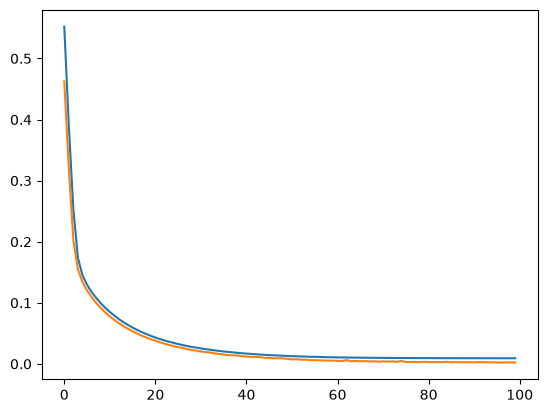

In [292]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

In [291]:
history.history

{'accuracy': [0.7956249713897705,
  0.7956249713897705,
  0.7956249713897705,
  0.8973437547683716,
  0.9887499809265137,
  0.9945312738418579,
  0.9964062571525574,
  0.9975000023841858,
  0.9975000023841858,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9979687333106995,
  0.9981250166893005,
  0.9981250166893005,
  0.9979687333106995,
  0.9981250166893005,
  0.9981250166893005,
  0.9981250166893005,
  0.9981250166893005,
  0.9979687333106995,
  0.9982812404632568,
  0.9982812404632568,
  0.9982812404632568,
  0.9982812404632568

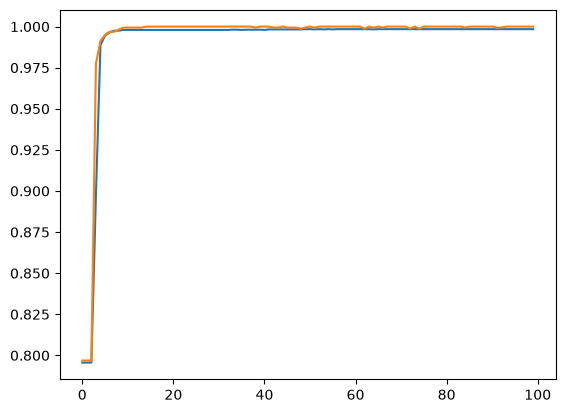

In [293]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])